# 06 — Deep learning: LSTM, GRU, walk-forward validation, ARIMA + LSTM hybrid

> **Python only** (PyTorch). The brief (§8.1) allows the advanced block (§4) in a single language, provided it is clearly stated.

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 6.

| | |
|---|---|
| **Input** | `data/processed/panel.parquet`, split from `config.yaml`, ARIMA from Phase 3 |
| **Outputs** | `results/forecasts_dl.csv` (common format), `results/06_*.csv`, `figures/fig_06_*.png` |
| **Brief** | §4.1 (LSTM and GRU, sliding windows, scaling, justified hyperparameters, loss curves, walk-forward validation), §4.2 (hybrid), §6 (forecasts h = 5 and 10) |

**Target:** as for the ARIMA, the log level of **CONVERTS**. The network forecasts the **returns** of the next 10 days, and the forecast log level is the last known log level plus the sum of the forecast returns.

**Direct multi-step forecasting:** a single network outputs the 10 future returns at once. Why not recursive forecasting: the inputs contain the returns of BTC and NVDA, which are unknown in the future. A recursion would need a second model for them and would accumulate its errors.

**Prophet (§4.3, optional)** is not used: Phase 2 showed there is no seasonality at all, which is precisely what Prophet models.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, time, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from src import config, data, arima, dl, plotting

SEED = config.set_seed()
dl.set_torch_seed(SEED)      # torch seed + deterministic kernels + 1 thread -> identical results on every run
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 180, "display.max_columns", 30, "display.precision", 4)
RES = config.path("results")
warnings.filterwarnings("ignore", category=FutureWarning)
print("root:", ROOT.name, "| seed:", SEED, "| torch", torch.__version__, "| deterministic:", torch.are_deterministic_algorithms_enabled())

root: Bitcoin miners | seed: 42 | torch 2.15.0+cpu | deterministic: True


## 1. Data shaping: variables, scaling, sliding windows

**Two input sets are compared:**
* **univariate**: the CONVERTS return alone;
* **exogenous**: the CONVERTS return, the BTC and NVDA returns (the factors found in Phase 4), and the 20-day realised volatility of CONVERTS.

**Scaling**: `StandardScaler` **fitted on the training sample only**, then applied as is to the test set, so that no test information enters the means and standard deviations. The target (the 10 future CONVERTS returns) is scaled with the parameters of the "CONVERTS return" column.

**Windows**: X = the last w days of variables, Y = the next 10 returns. We test **w = 10, 20, 40** (two weeks, one month, two months of trading). A longer window can capture volatility regimes, but it reduces the number of examples and increases the risk of overfitting.

**Internal validation** (for early stopping): the **last 15%** of the training windows, in chronological order. **10 separation windows** are removed between the two parts, because their 10-day targets would overlap the validation period.

In [2]:
# Feature matrix on the trading calendar; rows start once the 20-day realised volatility exists.
panel = data.load_panel()
train, test = data.chrono_split(panel)
H = 10
feat = pd.DataFrame({"r_CONVERTS": panel["CONVERTS_log_return"], "r_BTC": panel["BTC_log_return"],
                     "r_NVDA": panel["NVDA_log_return"], "rv20_CONVERTS": panel["CONVERTS_rv20"]}).dropna()
logy = panel["CONVERTS_log_price"].loc[feat.index]
pos_train_end = feat.index.get_loc(train.index[-1])
INPUTS = {"univariate": ["r_CONVERTS"], "exogenous": ["r_CONVERTS", "r_BTC", "r_NVDA", "rv20_CONVERTS"]}
scaler = StandardScaler().fit(feat.iloc[: pos_train_end + 1])          # TRAIN rows only
Fz = pd.DataFrame(scaler.transform(feat), index=feat.index, columns=feat.columns)
mu_r, sd_r = scaler.mean_[0], scaler.scale_[0]                         # to unscale the predicted returns
target_z = Fz["r_CONVERTS"].to_numpy()
print(f"rows {len(feat)} ({feat.index[0].date()} -> {feat.index[-1].date()}) | train end at row {pos_train_end} | target mean {mu_r:.5f}, sd {sd_r:.5f}")

rows 1205 (2022-01-12 -> 2026-10-30) | train end at row 1081 | target mean 0.00122, sd 0.06343


In [3]:
# Window ends usable for training: full window inside the data AND the 10 target days inside the TRAIN period.
def ends_for(w):
    return np.arange(w - 1, pos_train_end - H + 1)

def dataset(w, inputs, ends):
    return dl.make_windows(Fz[INPUTS[inputs]].to_numpy(), target_z, w, H, ends)

for w in (10, 20, 40):
    tr, va = dl.split_train_val(ends_for(w))
    print(f"w = {w}: {len(tr)} training windows, {len(va)} validation windows ({feat.index[va[0]].date()} -> {feat.index[va[-1]].date()})")

w = 10: 894 training windows, 159 validation windows (2025-09-04 -> 2026-04-22)
w = 20: 886 training windows, 157 validation windows (2025-09-08 -> 2026-04-22)
w = 40: 869 training windows, 154 validation windows (2025-09-11 -> 2026-04-22)


## 2. LSTM and GRU: same budget, small explicit grid

| Hyperparameter | Value | Justification |
|---|---|---|
| Recurrent layers | 1 | fewer than 900 training windows: a 2nd layer would multiply the parameters with no data to estimate them |
| Hidden units | 32 | 4,810 to 5,194 parameters (LSTM), 3,690 to 3,978 (GRU): a few times the number of examples (≈ 870 to 894 windows); beyond that, the network memorises noise |
| Dropout | 0.2 | Standard regularisation on the output of the recurrent layer |
| Optimiser | Adam, lr = 0.001 | Robust default value, no fine-tuning on the test data |
| Batch | 64 | Trade-off between gradient stability and number of updates per epoch |
| Epochs | ≤ 150, early stopping (patience 15) | The weights of the best validation loss are kept: limits overfitting |
| Loss function | MSE on the 10 scaled returns | Consistent with the RMSE used to compare models |

**Grid**: window w ∈ {10, 20, 40} × inputs {univariate, exogenous} × cell {LSTM, GRU}, i.e. 12 models. The best configuration of each cell is kept according to the **validation loss**.

**Benchmark**: the validation loss of a **zero** forecast (future return = 0, i.e. the random walk). A ratio above 1 means the network does worse than the random walk.

In [4]:
# 12 fits, each with the same budget; validation loss of the zero forecast (random walk) as the yardstick.
grid, models, hists = [], {}, {}
for w in (10, 20, 40):
    tr_e, va_e = dl.split_train_val(ends_for(w))
    for inputs in INPUTS:
        Xtr, Ytr = dataset(w, inputs, tr_e); Xva, Yva = dataset(w, inputs, va_e)
        rw_loss = float(np.mean((Yva - (-mu_r / sd_r)) ** 2))       # zero raw return, expressed on the scaled axis
        for kind in ("lstm", "gru"):
            t0 = time.time()
            m, h = dl.train_model(kind, Xtr, Ytr, Xva, Yva, seed=SEED)
            models[(kind, w, inputs)], hists[(kind, w, inputs)] = m, h
            best = h["val_loss"].min()
            grid.append({"cell": kind.upper(), "window": w, "inputs": inputs, "epochs": len(h),
                         "best epoch": int(h["val_loss"].idxmin()) + 1, "val_loss": best, "val_loss RW": rw_loss,
                         "ratio vs RW": best / rw_loss, "parameters": sum(p.numel() for p in m.parameters()),
                         "seconds": round(time.time() - t0, 1)})
grid = pd.DataFrame(grid)
grid.to_csv(RES / "06_grid.csv", index=False)
grid.sort_values(["cell", "val_loss"])

,cell,window,inputs,epochs,best epoch,val_loss,val_loss RW,ratio vs RW,parameters,seconds
3,GRU,10,exogenous,22,7,0.8676,0.8720,0.9950,3978,2.0
7,GRU,20,exogenous,21,6,0.8682,0.8721,0.9955,3978,2.2
1,GRU,10,univariate,20,5,0.8713,0.8720,0.9992,3690,1.6
5,GRU,20,univariate,21,6,0.8716,0.8721,0.9994,3690,2.0
11,GRU,40,exogenous,22,7,0.8724,0.8763,0.9956,3978,4.1
9,GRU,40,univariate,22,7,0.8756,0.8763,0.9992,3690,4.0
2,LSTM,10,exogenous,22,7,0.8691,0.8720,0.9967,5194,1.3
6,LSTM,20,exogenous,21,6,0.8694,0.8721,0.9969,5194,1.2
0,LSTM,10,univariate,22,7,0.8716,0.8720,0.9996,4810,1.6
4,LSTM,20,univariate,24,9,0.8719,0.8721,0.9997,4810,1.8


In [5]:
# Best configuration of each cell by validation loss.
best_cfg = {k.lower(): tuple(grid[grid["cell"] == k].sort_values("val_loss").iloc[0][["window", "inputs"]])
            for k in ("LSTM", "GRU")}
best_cfg

{'lstm': (np.int64(10), 'exogenous'), 'gru': (np.int64(10), 'exogenous')}

**Reading the grid.**
* **All models end up at the level of the random walk.** The ratio of validation loss to random-walk loss is between **0.995 and 0.9997**: at best, the network reduces the error by 0.5%. What it learned lies almost entirely in the mean of the returns.
* **The exogenous inputs (BTC, NVDA, volatility) help a little**, consistently: ratio 0.995–0.997 vs 0.999–0.9997 for univariate, for both cells and all windows.
* **The short window (w = 10) is the best.** Long windows add nothing, which is consistent with the absence of long dynamics in Phases 3 and 4.
* **Chosen configurations: LSTM and GRU with w = 10 and exogenous inputs.** GRU gets the smallest validation loss (0.8676 vs 0.8691), with fewer parameters.
* **Early stopping kicks in very early** (best epoch between 5 and 9): after a few epochs, the network starts learning the noise of the training sample.

## 3. Courbes d'apprentissage (perte train vs validation)

figures\fig_06_01_training_curves.png


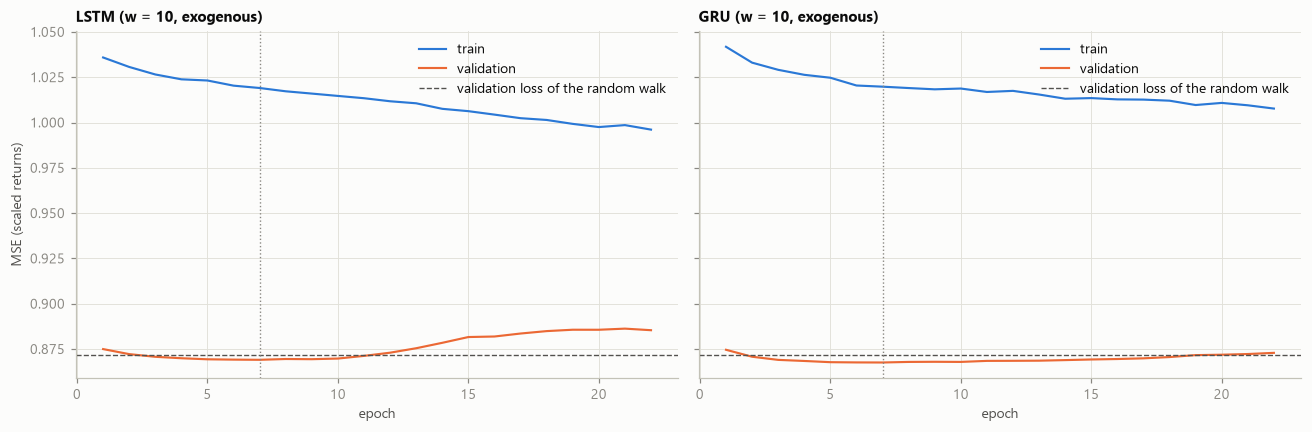

In [6]:
# Training curves of the two selected models; the dashed line is the random-walk validation loss.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ("lstm", "gru")):
    w, inputs = best_cfg[kind]
    h = hists[(kind, w, inputs)]
    ax.plot(h["epoch"], h["train_loss"], color=plotting.SERIES[0], label="train")
    ax.plot(h["epoch"], h["val_loss"], color=plotting.SERIES[1], label="validation")
    rw = grid[(grid["cell"] == kind.upper()) & (grid["window"] == w) & (grid["inputs"] == inputs)]["val_loss RW"].iloc[0]
    ax.axhline(rw, color=plotting.INK2, ls="--", lw=0.9, label="validation loss of the random walk")
    ax.axvline(h["val_loss"].idxmin() + 1, color=plotting.MUTED, ls=":", lw=0.9)
    ax.set_title(f"{kind.upper()} (w = {w}, {inputs})"); ax.set_xlabel("epoch"); ax.legend(loc="upper right")
axes[0].set_ylabel("MSE (scaled returns)")
fig.tight_layout(); print(plotting.save(fig, "fig_06_01_training_curves")); plt.show()

* **The training loss falls continuously**, from 1.04 to ≈ 1.00: the network "explains" the training data better and better.
* **The validation loss falls only for ≈ 7 epochs**, and very little, just below the random-walk line. After that:
  * for the LSTM, it **rises clearly** beyond 10 epochs (up to ≈ 0.886): this is **overfitting**;
  * for the GRU, it rises more slowly.

  Early stopping keeps the weights of the best epoch (dotted line).
* **No underfitting in the usual sense.** There is practically nothing to learn, and the gap between the curves is the signature of a model memorising noise.
* **Why validation is below training.** The two losses cannot be compared in level: the validation period (September 2025 – April 2026) is less volatile than the training average, so its scaled returns have a lower variance.

## 4. Time-series cross-validation (walk-forward, expanding window)

`TimeSeriesSplit` with **5 expanding-window folds** on the training windows, with a gap of 10 windows between the training and test parts of each fold. Fold k trains on everything before its test block, and the model never sees the future. **Never classical k-fold**, which would mix past and future.

In each fold:
* the chosen configuration is retrained, with early stopping on the last 15% of its own training part;
* RMSE and MAE of the error on the **log level** are measured at h = 1, 5 and 10;
* the result is compared with the random walk on the same block.

In [7]:
# 5 expanding folds per selected model; RMSE / MAE of the log-level error vs the random walk on the same block.
tss = TimeSeriesSplit(n_splits=5, gap=H)
wf = []
for kind in ("lstm", "gru"):
    w, inputs = best_cfg[kind]
    ends = ends_for(w)
    for k, (tr_i, te_i) in enumerate(tss.split(ends), 1):
        fit_e, es_e = dl.split_train_val(ends[tr_i])
        m, _ = dl.train_model(kind, *dataset(w, inputs, fit_e), *dataset(w, inputs, es_e), seed=SEED)
        Xte, Yte = dataset(w, inputs, ends[te_i])
        y_true = Yte * sd_r + mu_r
        err_m = dl.cum_errors(y_true, dl.predict(m, Xte) * sd_r + mu_r)
        err_rw = dl.cum_errors(y_true, np.zeros_like(y_true))
        for h in (1, 5, 10):
            wf.append({"model": kind.upper(), "fold": k, "test start": feat.index[ends[te_i][0]].date(), "test end": feat.index[ends[te_i][-1]].date(),
                       "n test": len(te_i), "h": h,
                       "RMSE model": np.sqrt(np.mean(err_m[:, h - 1] ** 2)), "RMSE RW": np.sqrt(np.mean(err_rw[:, h - 1] ** 2)),
                       "MAE model": np.mean(np.abs(err_m[:, h - 1])), "MAE RW": np.mean(np.abs(err_rw[:, h - 1]))})
wf = pd.DataFrame(wf)
wf["ratio RMSE"] = wf["RMSE model"] / wf["RMSE RW"]
wf.to_csv(RES / "06_walk_forward_folds.csv", index=False)
wf_sum = wf.groupby(["model", "h"]).agg(RMSE_mean=("RMSE model", "mean"), RMSE_std=("RMSE model", "std"),
                                          MAE_mean=("MAE model", "mean"), MAE_std=("MAE model", "std"),
                                          RMSE_RW_mean=("RMSE RW", "mean"), ratio_mean=("ratio RMSE", "mean"),
                                          folds_better_than_RW=("ratio RMSE", lambda x: int((x < 1).sum())))
wf_sum.to_csv(RES / "06_walk_forward_summary.csv")
wf_sum

RMSE_mean  RMSE_std  MAE_mean  MAE_std  RMSE_RW_mean  ratio_mean  folds_better_than_RW
model h                                                                                         
GRU   1      0.0644    0.0042    0.0499   0.0027        0.0638      1.0081                     1
      5      0.1472    0.0164    0.1169   0.0109        0.1462      1.0068                     3
      10     0.2061    0.0259    0.1676   0.0178        0.2058      1.0005                     3
LSTM  1      0.0640    0.0040    0.0499   0.0028        0.0638      1.0023                     1
      5      0.1458    0.0179    0.1162   0.0120        0.1462      0.9962                     3
      10     0.2061    0.0280    0.1677   0.0195        0.2058      0.9990                     3

figures\fig_06_02_walk_forward.png


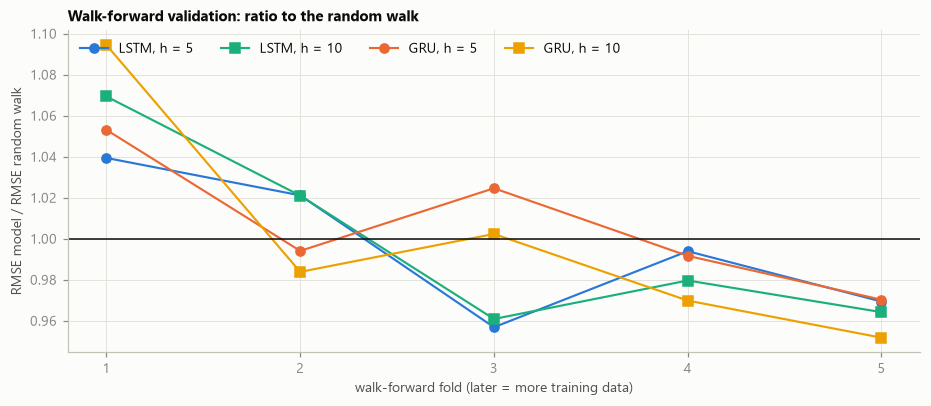

In [8]:
# Fold-by-fold ratio to the random walk (below 1 = the network beats the random walk on that block).
fig, ax = plt.subplots(figsize=(10, 3.8))
for (kind, h), col, mk in zip([(k, h) for k in ("LSTM", "GRU") for h in (5, 10)],
                              [plotting.SERIES[0], plotting.SERIES[2], plotting.SERIES[1], plotting.SERIES[3]], "osos"):
    k = wf[(wf["model"] == kind) & (wf["h"] == h)]
    ax.plot(k["fold"], k["ratio RMSE"], marker=mk, color=col, label=f"{kind}, h = {h}")
ax.axhline(1, color=plotting.INK, lw=1); ax.set_xticks(range(1, 6))
ax.set_xlabel("walk-forward fold (later = more training data)"); ax.set_ylabel("RMSE model / RMSE random walk")
ax.set_title("Walk-forward validation: ratio to the random walk"); ax.legend(loc="upper left", ncol=4)
print(plotting.save(fig, "fig_06_02_walk_forward")); plt.show()

**Results over 5 folds (mean ± std; error on the log level, compared with the random walk on the same blocks):**

| Model | h | Mean RMSE (± std) | Random-walk RMSE | Mean ratio | Folds better than the random walk |
|---|---|---|---|---|---|
| LSTM | 1 | 0.0640 (± 0.0040) | 0.0638 | 1.002 | 1 / 5 |
| LSTM | 5 | 0.1458 (± 0.0179) | 0.1462 | 0.996 | 3 / 5 |
| LSTM | 10 | 0.2061 (± 0.0280) | 0.2058 | 0.999 | 3 / 5 |
| GRU | 1 | 0.0644 (± 0.0042) | 0.0638 | 1.008 | 1 / 5 |
| GRU | 5 | 0.1472 (± 0.0164) | 0.1462 | 1.007 | 3 / 5 |
| GRU | 10 | 0.2061 (± 0.0259) | 0.2058 | 1.001 | 3 / 5 |

* **Ratio close to 1.** Over the five periods, both networks win in some folds and lose in others, by about one percent. The std across folds (≈ 0.017 at h = 5) is **much larger** than the mean difference from the random walk (0.0004 for the LSTM, 0.001 for the GRU): no superiority is shown.
* **Interpretation.** An RMSE of 0.146 on the 5-day log level means a typical error of about 15% on the index. This number is set by the volatility of CONVERTS, not by the model.
* **GRU chosen by internal validation.** The GRU was slightly better on its validation period, but not in walk-forward. A single validation period is not enough to separate such close models, and that is precisely why time-series cross-validation is required.

## 5. ARIMA + LSTM hybrid (brief §4.2, bonus)

Principle (Zhang, 2003): y = linear part + non-linear part.
* The ARIMA models the linear part.
* An LSTM learns the remaining structure in the ARIMA **residuals**.
* Final forecast = ARIMA forecast + LSTM forecast of the future residuals (cumulated over the horizon for the log level).

**Choice of the linear part.** The model chosen in Phase 3 is ARIMA(0,1,0) without drift. Its residuals are **exactly the returns**, so a hybrid built on it would be identical to the univariate LSTM of section 2. We therefore use **ARIMA(0,1,1)**, the best by AIC in Phase 3, so that the decomposition makes sense. Its parameters are estimated on the training sample, then applied as is to the test set. The residual LSTM reuses the window of the best LSTM configuration, with univariate input.

In [9]:
# Linear part: ARIMA(0,1,1) fitted on train, applied with FIXED parameters to the whole series to get residuals everywhere.
ar = arima.fit_arima(logy.loc[: train.index[-1]], (0, 1, 1))
ar_full = ar.apply(logy.to_numpy())
resid = pd.Series(ar_full.resid, index=logy.index); resid.iloc[0] = 0.0      # first residual = diffuse start, not a shock
rs = StandardScaler().fit(resid.iloc[: pos_train_end + 1].to_frame())
resid_z = rs.transform(resid.to_frame()).ravel()
w_h = best_cfg["lstm"][0]
tr_e, va_e = dl.split_train_val(ends_for(w_h))
mk_res = lambda e: dl.make_windows(resid_z[:, None], resid_z, w_h, H, e)
m_hyb, h_hyb = dl.train_model("lstm", *mk_res(tr_e), *mk_res(va_e), seed=SEED)
Yva_r = mk_res(va_e)[1]
print(f"MA(1) theta = {ar.params[0]:.4f} | residual-LSTM: window {w_h}, best epoch {h_hyb['val_loss'].idxmin() + 1}, "
      f"val loss {h_hyb['val_loss'].min():.4f} vs zero-forecast {np.mean((Yva_r - (-rs.mean_[0] / rs.scale_[0])) ** 2):.4f}")

MA(1) theta = 0.0468 | residual-LSTM: window 10, best epoch 7, val loss 0.8695 vs zero-forecast 0.8698


**Result.** The MA(1) parameter θ is 0.047, a very weak linear part. The LSTM trained on the residuals reaches a validation loss of 0.8695, vs **0.8698 for a zero forecast of the residuals**: it finds **practically no non-linear structure** in the residuals. Phases 3 and 5 suggested this: the CONVERTS residuals are neither autocorrelated (Ljung-Box) nor heteroscedastic (ARCH-LM). The hybrid forecast is therefore almost identical to the ARIMA(0,1,1) one.

## 6. Forecasts h = 5 and h = 10 on the test set (common format)

We use the final models (best LSTM configuration, best GRU configuration, hybrid), trained on the training sample with early stopping. They are **never retrained** on the test set. The origins are the same as in Phases 3 to 5: the last training day, then each test day. At each origin, the input window contains only data already observed.

**95% intervals**: a network gives no analytical interval. We take the 2.5% and 97.5% quantiles of the **validation errors** on the log level, at each horizon, and add them to the forecast.

In [10]:
# Forecast from every origin; empirical intervals from each model's validation errors.
origins = feat.index[pos_train_end: len(feat) - 1]
pos_o = np.array([feat.index.get_loc(o) for o in origins])
fc_parts = []
for kind in ("lstm", "gru"):
    w, inputs = best_cfg[kind]; m = models[(kind, w, inputs)]
    tr_e, va_e = dl.split_train_val(ends_for(w))
    Xva, Yva = dataset(w, inputs, va_e)
    ev = dl.cum_errors(Yva * sd_r + mu_r, dl.predict(m, Xva) * sd_r + mu_r)
    Xo = np.stack([Fz[INPUTS[inputs]].to_numpy()[p - w + 1: p + 1] for p in pos_o]).astype(np.float32)
    pr = dl.predict(m, Xo) * sd_r + mu_r
    fc_parts.append(dl.rolling_level_forecasts(pr, logy, origins, H, kind, "CONVERTS", np.quantile(ev, 0.025, axis=0), np.quantile(ev, 0.975, axis=0)))
# Hybrid: ARIMA(0,1,1) log forecast + cumulated LSTM residual forecast.
Xo = np.stack([resid_z[p - w_h + 1: p + 1, None] for p in pos_o]).astype(np.float32)
res_pred = dl.predict(m_hyb, Xo) * rs.scale_[0] + rs.mean_[0]
ar_paths = np.array([ar.apply(logy.to_numpy()[: p + 1]).forecast(H) for p in pos_o])
hyb_ret = np.diff(np.column_stack([logy.to_numpy()[pos_o], ar_paths]), axis=1) + res_pred   # ARIMA step changes + residual forecast
Xv = mk_res(va_e)[0]
va_pos = va_e
ar_va = np.array([ar.apply(logy.to_numpy()[: p + 1]).forecast(H) for p in va_pos])
true_va = np.array([logy.to_numpy()[p + 1: p + 1 + H] for p in va_pos])
pred_va = ar_va + np.cumsum(dl.predict(m_hyb, Xv) * rs.scale_[0] + rs.mean_[0], axis=1)
ev_h = true_va - pred_va
fc_parts.append(dl.rolling_level_forecasts(hyb_ret, logy, origins, H, "hybrid_arima_lstm", "CONVERTS",
                                           np.quantile(ev_h, 0.025, axis=0), np.quantile(ev_h, 0.975, axis=0)))
fc_dl = pd.concat(fc_parts, ignore_index=True)
fc_dl.to_csv(RES / "forecasts_dl.csv", index=False, date_format="%Y-%m-%d")
rw = pd.read_csv(RES / "forecasts_arima.csv", parse_dates=["date", "origin"]).query("series == 'CONVERTS' and model == 'rw'")
sc = arima.quick_scores(pd.concat([rw, fc_dl], ignore_index=True))
sc.to_csv(RES / "06_forecast_scores_preview.csv", index=False)
sc

,model,series,horizon,n_origins,RMSE,MAE,MAPE_%,coverage_95%
0,rw,CONVERTS,5,119,28.7678,23.4698,10.4713,96.6387
1,rw,CONVERTS,10,114,36.0976,28.2671,13.6126,98.2456
2,lstm,CONVERTS,5,119,29.5294,24.2013,10.9003,96.6387
3,lstm,CONVERTS,10,114,38.5344,29.7094,14.7516,90.3509
4,gru,CONVERTS,5,119,30.1337,24.7797,11.2288,96.6387
5,gru,CONVERTS,10,114,40.0696,30.8609,15.3945,90.3509
6,hybrid_arima_lstm,CONVERTS,5,119,29.0919,23.8103,10.6202,96.6387
7,hybrid_arima_lstm,CONVERTS,10,114,36.9897,29.0904,13.9728,93.8596


In [11]:
# Seed sensitivity: retrain the two selected models with two other seeds and score them on the test set.
seeds = []
for kind in ("lstm", "gru"):
    w, inputs = best_cfg[kind]
    tr_e, va_e = dl.split_train_val(ends_for(w))
    Xo = np.stack([Fz[INPUTS[inputs]].to_numpy()[p - w + 1: p + 1] for p in pos_o]).astype(np.float32)
    for sd in (SEED, 1, 2):
        m = models[(kind, w, inputs)] if sd == SEED else dl.train_model(kind, *dataset(w, inputs, tr_e), *dataset(w, inputs, va_e), seed=sd)[0]
        f = dl.rolling_level_forecasts(dl.predict(m, Xo) * sd_r + mu_r, logy, origins, H, kind, "CONVERTS", np.zeros(H), np.zeros(H))
        s = arima.quick_scores(f)
        seeds.append({"model": kind.upper(), "seed": sd, **{f"RMSE h={h}": s.loc[s["horizon"] == h, "RMSE"].iloc[0] for h in (5, 10)}})
dl.set_torch_seed(SEED)
seeds = pd.DataFrame(seeds)
seeds.to_csv(RES / "06_seed_sensitivity.csv", index=False)
seeds

,model,seed,RMSE h=5,RMSE h=10
0,LSTM,42,29.5294,38.5344
1,LSTM,1,29.8854,39.8545
2,LSTM,2,30.0719,39.0959
3,GRU,42,30.1337,40.0696
4,GRU,1,29.9711,39.4617
5,GRU,2,30.2195,40.1212


figures\fig_06_03_forecasts_h5.png


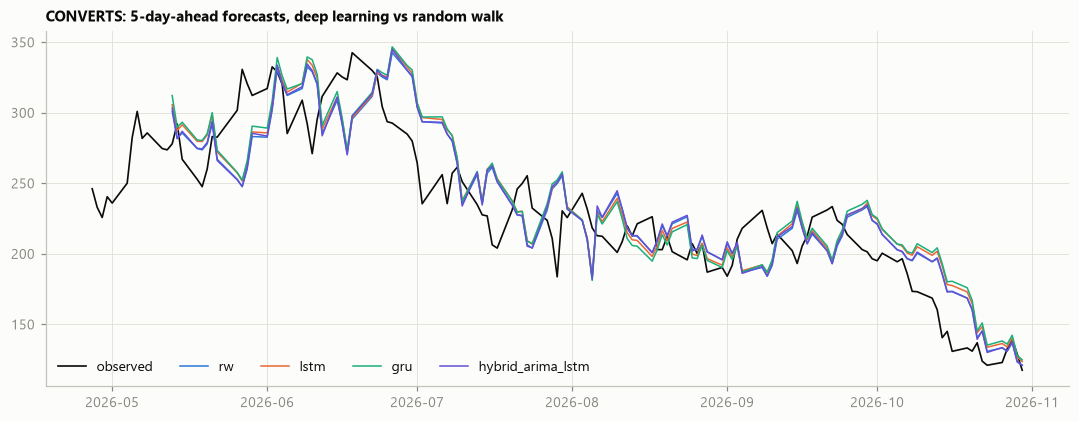

In [12]:
# 5-day-ahead forecasts on the test set: networks vs random walk.
fig, ax = plt.subplots(figsize=(12, 4.2))
obs = np.exp(logy).loc[test.index[0] - pd.Timedelta(days=10):]
ax.plot(obs.index, obs, color=plotting.INK, lw=1.1, label="observed")
for m, col in [("rw", plotting.CORE["CONVERTS"]), ("lstm", plotting.SERIES[1]), ("gru", plotting.SERIES[2]), ("hybrid_arima_lstm", plotting.SERIES[6])]:
    k = pd.concat([rw, fc_dl])
    k = k[(k["model"] == m) & (k["horizon"] == 5)]
    ax.plot(k["date"], k["y_pred"], lw=1, color=col, label=m)
ax.set_title("CONVERTS: 5-day-ahead forecasts, deep learning vs random walk"); ax.legend(loc="lower left", ncol=5)
print(plotting.save(fig, "fig_06_03_forecasts_h5")); plt.show()

**Accuracy on the test set** (RMSE in index points; 119 origins at h = 5, 114 at h = 10):

| Model | RMSE h=5 | RMSE h=10 | MAPE h=5 | MAPE h=10 | 95% coverage h=5 / h=10 |
|---|---|---|---|---|---|
| **rw** (Phase 3) | **28.77** | **36.10** | **10.5%** | **13.6%** | 96.6% / 98.2% |
| lstm | 29.53 | 38.53 | 10.9% | 14.8% | 96.6% / 90.4% |
| gru | 30.13 | 40.07 | 11.2% | 15.4% | 96.6% / 90.4% |
| hybrid_arima_lstm | 29.09 | 36.99 | 10.6% | 14.0% | 96.6% / 93.9% |

* **No deep-learning model beats the random walk on the test set.** The closest is the hybrid (+1.1% RMSE at h = 5), precisely because its LSTM component does almost nothing. The LSTM (+2.6%) and the GRU (+4.7%) are worse, and the gap grows at h = 10.
* **The networks forecast an upward drift.** Between h = 1 and h = 10, the forecast rises on average by 1.6% (LSTM), 2.0% (GRU) and 0.55% (hybrid), reflecting the positive mean return of the training sample. On this test set, marked by a sharp fall at the end, this drift adds error: it comes from the training sample and does not repeat on the test set. This is also why the gap with the random walk grows at h = 10.
* **Empirical intervals**: coverage at h = 10 falls to 90% (LSTM, GRU), below the nominal 95%. The validation errors (a rather calm period) underestimate the uncertainty of the test set.
* **Seed sensitivity.** With seeds 1 and 2, the RMSE at h = 5 ranges from 29.5 to 30.1 (LSTM) and from 30.0 to 30.2 (GRU): always above the random walk's (28.77). The conclusion does not depend on the luck of initialisation.

## 7. Honest comparison with the random walk

**Deep learning does not beat the random walk, neither in walk-forward validation (ratio 0.996 to 1.008) nor on the test set (RMSE 29.1 to 30.1 vs 28.8 at h = 5).** This is an **expected** result for financial returns, for four reasons:

1. **Returns are almost unpredictable.** Phases 2 to 4 found no autocorrelation (Ljung-Box), no dynamics (VAR, p = 0) and no Granger causality. If past information allowed stable prediction, it would quickly be exploited and therefore absorbed into prices (efficient market hypothesis, at least in its weak form).
2. **The signal-to-noise ratio is very low.** The daily volatility of CONVERTS is ≈ 6%, for a mean return of ≈ 0.01%. A flexible network therefore mostly finds noise to memorise, as the loss curves show.
3. **There is little data for a network.** Fewer than 900 windows for several thousand parameters, and a regime change (the pivot) in the middle.
4. **The test set is a particular regime** (sharp fall at the end of the period), which no training data could anticipate.

**What we can keep:**
* the BTC and NVDA inputs help slightly in validation, which is consistent with Phase 4 (same-day link, but no predictive link);
* the hybrid does no better than its ARIMA, for lack of non-linearity in the residuals;
* the only model that has beaten the random walk so far is the **CONVERTS–NVDA VECM** (Phase 4), which exploits a long-run relationship, not short-run dynamics.

Phase 7 tests these differences formally (Diebold-Mariano).

## Phase 6 summary

1. **Grid of 12 models** (windows 10 / 20 / 40, univariate or exogenous inputs, LSTM / GRU, 1 layer of 32 units, dropout 0.2, early stopping): all end up at the random-walk level (validation-loss ratio 0.995 to 0.9997). Best configuration: w = 10 with BTC, NVDA and volatility as inputs.
2. **The loss curves show fast overfitting**: validation loss rises after ≈ 7 to 10 epochs, hence early stopping between epochs 5 and 9.
3. **Walk-forward (5 expanding folds)**: RMSE at h = 5 of 0.146 ± 0.018 (LSTM) vs 0.146 for the random walk. Mean ratio 0.996 to 1.008, and only 3 folds out of 5 won: no superiority.
4. **ARIMA(0,1,1) + LSTM hybrid**: the LSTM finds no structure in the residuals (loss 0.8695 vs 0.8698), consistent with the absence of autocorrelation and ARCH effect.
5. **Test**: RMSE at h = 5 of 29.1 (hybrid), 29.5 (LSTM) and 30.1 (GRU), vs 28.8 for the random walk, independent of the seed. **Deep learning does not beat the random walk**, as expected for financial returns.